# YSA F26 | Bütün deneyler — Tek Google Colab ortamı

**El yazısı rakam sınıflandırma: yeniden üretim çalışması**

Bu defter, daha önce Mac Terminal ve ayrı Colab defterlerinde yürütülen **deney yöntemlerini tek bir yeni Colab çalıştırmasında** bir araya getirir. **Önceki Mac ve GitHub çıktılarını değiştirmez.** Eski sayısal sonuçlar bu deftere yapıştırılmaz; yeni sonuçlar yeni eğitimin gerçek çıktılarıdır.

**Tek Colab oturumunda sırasıyla:**

1. **Ana deney:** Beş klasik modelin 5-katlı hiperparametre araması ve MLP-A, MLP-B, CNN-C eğitimleri. Nihai seçim doğrulama makro F1 ile; ardından test.
2. **CNN-C kararlılığı:** Aynı sabit veri ayrımında 101, 202, 303, 404, 505 tohumlarıyla beş ayrı CNN eğitimi ve tümünün test değerlendirmesi. Teste göre tohum seçimi yoktur.
3. **Mimari / düzenlileştirme analizi:** Üç CNN yapılandırması × üç ortak tohum = dokuz eğitim; yalnızca eğitim ve doğrulama verisi kullanılır. **Test edilmez.**
4. **Kayıt ve denetim:** Sürümler, donanım, veri bölünmesi indeksleri, tahminler, tüm sinir ağı modelleri, eğitim geçmişleri, tablolar, grafikler ve deney planları tek ZIP arşivinde saklanır.

**Çalıştırma:** Google Colab’da `.ipynb` dosyasını açın. `Çalışma zamanı → Tümünü çalıştır` seçin. Bağımsız veri yüklemek gerekmez (`sklearn.datasets.load_digits()`). Eğitimler uzun sürebilir. Son hücre `=== TAMAMLANDI ===` yazdıktan sonra ZIP otomatik indirilir. Ayrıca `Dosya → İndir → .ipynb` ile **çıktılı** defteri bilgisayara kaydedin.

**Yöntem notu:** Aynı *veri bölünmesi* ve aynı *Colab çalışma zamanı* bütün bölümlerde kullanılır. Önceki Mac koşuları ayrı yeniden üretim kayıtlarıdır; farklı donanım/kütüphane sürümleri nedeniyle sayısal skorlar aynı olmak zorunda değildir. Ek deneyler, önceden incelenmiş test sonuçlarından sonra tasarlandığı için keşifseldir ve yeni bağımsız test verisi olarak sunulamaz.

**Colab bağlantısı kesilirse:** Geçici Colab dosyaları kaybolabilir. A ve B aşamalarının sonunda oluşturulan ara ZIP’leri isterseniz sol taraftaki **Dosyalar** panelinden bilgisayarınıza indirebilirsiniz. Ana ZIP ancak bütün aşamalar bitince oluşur.

## Bölüm A — Ana deney: 5 klasik model + MLP-A + MLP-B + CNN-C

Aşağıdaki bölüm mevcut ana deney kodunun **aynı yöntemini ve hiperparametre aramalarını** izler.

In [1]:
import os, random, warnings, json
from pathlib import Path
from datetime import datetime, timezone
import platform, importlib.metadata, sys, gc

os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
    precision_recall_fscore_support
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers, regularizers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
FIG_DPI = 600
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_ROOT = Path("/content/ysa_f26_tek_colab") / RUN_ID if Path("/content").exists() else Path("ysa_f26_tek_colab") / RUN_ID
OUTPUT_DIR = OUTPUT_ROOT / "ana_deney"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Sabit seed:", SEED, "| Şekil çözünürlüğü:", FIG_DPI, "dpi")
print("Çalışma klasörü:", OUTPUT_ROOT)


TensorFlow: 2.21.0
Sabit seed: 42 | Şekil çözünürlüğü: 600 dpi
Çalışma klasörü: /content/ysa_f26_tek_colab/20261017T160921Z


## 1. Veri Seti ve İlgi Alanıyla İlişkisi

Digits veri seti, `0–9` arasındaki el yazısı rakamların görüntülerini içerir. Her görüntü 8×8 pikselden oluşur ve piksel yoğunlukları 0–16 aralığındadır. Bu problem doğrudan **görüntü işleme, bilgisayarlı görü, örüntü tanıma, yapay zekâ ve derin öğrenme** alanlarıyla ilgilidir.

Veri seti scikit-learn içinde hazır bulunduğundan ayrıca dosya yüklemeye veya internet bağlantısına gerek yoktur. Kaynak: UCI Optical Recognition of Handwritten Digits veri tabanının scikit-learn test alt kümesi.

In [2]:
digits = load_digits()
X = digits.data.astype("float32")          # (1797, 64)
images = digits.images.astype("float32")  # (1797, 8, 8)
y = digits.target.astype("int64")         # 0-9
class_names = np.array([str(i) for i in digits.target_names])

assert X.shape == (1797, 64)
assert images.shape == (1797, 8, 8)
assert len(np.unique(y)) == 10
assert not np.isnan(X).any()

print("Örnek sayısı:", len(X))
print("Görüntü boyutu:", images.shape[1:])
print("Özellik sayısı:", X.shape[1])
print("Sınıflar:", class_names.tolist())
print("Piksel aralığı:", float(X.min()), "-", float(X.max()))

Örnek sayısı: 1797
Görüntü boyutu: (8, 8)
Özellik sayısı: 64
Sınıflar: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Piksel aralığı: 0.0 - 16.0


## 2. Keşifsel Veri Analizi

In [3]:
# Tablo 1 — veri seti özeti
counts = pd.Series(y).value_counts().sort_index()
dataset_summary = pd.DataFrame({
    "Sınıf": counts.index,
    "Örnek_sayısı": counts.values,
    "Yüzde": (100 * counts.values / len(y)).round(2)
})
dataset_summary.to_csv(OUTPUT_DIR/"table_1_dataset_summary.csv", index=False)
display(dataset_summary)
print("Eksik değer:", int(np.isnan(X).sum()))
print("Sınıf büyüklüğü min/max farkı:", int(counts.max() - counts.min()))

,Sınıf,Örnek_sayısı,Yüzde
0,0,178,9.91
1,1,182,10.13
2,2,177,9.85
3,3,183,10.18
4,4,181,10.07
5,5,182,10.13
6,6,181,10.07
7,7,179,9.96
8,8,174,9.68
9,9,180,10.02


Eksik değer: 0
Sınıf büyüklüğü min/max farkı: 9


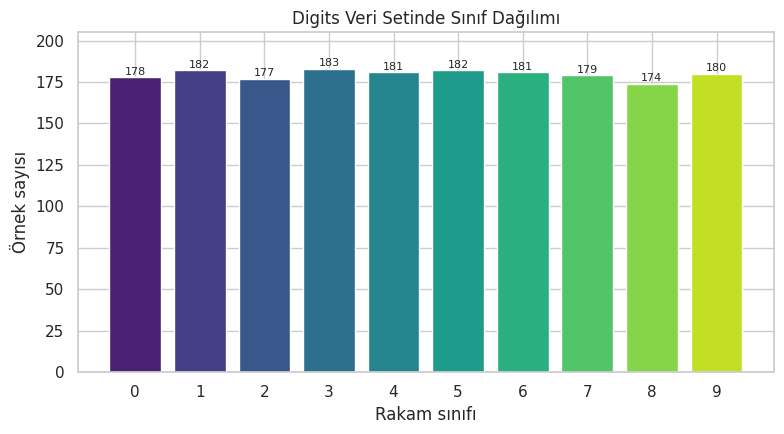

Yorum: Sınıflar dengelidir; en büyük ve en küçük sınıf arasındaki fark yalnızca 9 örnektir.


In [4]:
# Şekil 1 — sınıf dağılımı
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dataset_summary["Sınıf"].astype(str), dataset_summary["Örnek_sayısı"],
              color=sns.color_palette("viridis", 10))
for bar, value in zip(bars, dataset_summary["Örnek_sayısı"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+1.5, str(value), ha="center", fontsize=8)
ax.set(title="Digits Veri Setinde Sınıf Dağılımı", xlabel="Rakam sınıfı", ylabel="Örnek sayısı")
ax.set_ylim(0, dataset_summary["Örnek_sayısı"].max()*1.12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_1_class_distribution.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()
print("Yorum: Sınıflar dengelidir; en büyük ve en küçük sınıf arasındaki fark yalnızca",
      int(counts.max()-counts.min()), "örnektir.")

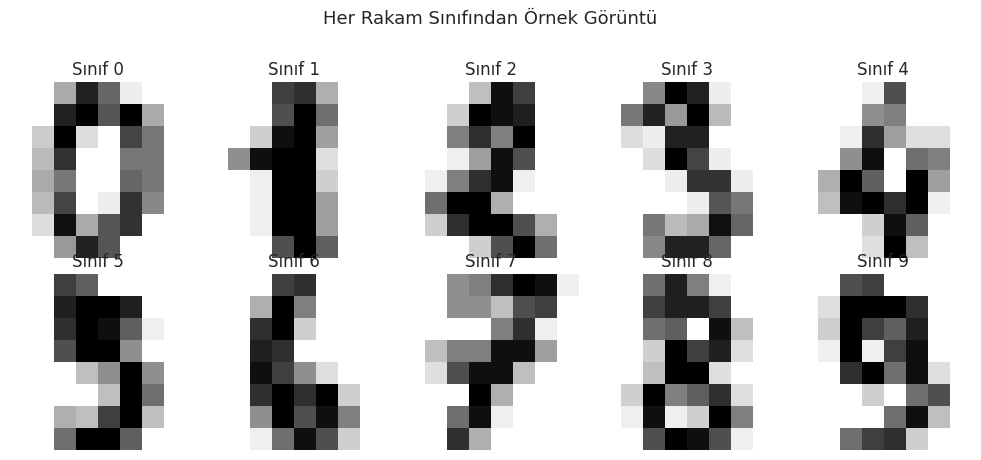

In [5]:
# Şekil 2 — her sınıftan bir örnek görüntü
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit, ax in enumerate(axes.ravel()):
    idx = np.flatnonzero(y == digit)[0]
    ax.imshow(images[idx], cmap="gray_r", interpolation="nearest")
    ax.set_title(f"Sınıf {digit}")
    ax.axis("off")
plt.suptitle("Her Rakam Sınıfından Örnek Görüntü", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_2_sample_images.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

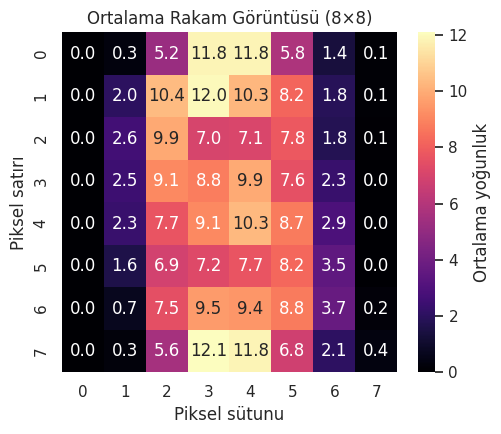

In [6]:
# Şekil 3 — tüm görüntülerin ortalama piksel yoğunluğu
fig, ax = plt.subplots(figsize=(5.2, 4.5))
sns.heatmap(images.mean(axis=0), cmap="magma", annot=True, fmt=".1f", cbar_kws={"label": "Ortalama yoğunluk"}, ax=ax)
ax.set_title("Ortalama Rakam Görüntüsü (8×8)")
ax.set_xlabel("Piksel sütunu"); ax.set_ylabel("Piksel satırı")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_3_mean_pixel_heatmap.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 3. Train / Validation / Test Ayrımı

- Training: %70 — öğrenme ve 5-fold CV hiperparametre araması
- Validation: %15 — algoritma ve sinir ağı mimarisi seçimi
- Test: %15 — bütün seçimlerden sonra bağımsız final değerlendirme

`stratify=y` ile her rakam sınıfının oranı üç alt kümede korunur. Bütün modeller aynı bölmeyi kullanır.

In [7]:
indices = np.arange(len(y))
idx_train, idx_temp = train_test_split(
    indices, test_size=0.30, stratify=y, random_state=SEED
)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED
)

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
img_train, img_val, img_test = images[idx_train], images[idx_val], images[idx_test]

split_rows = []
for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    row = {"Küme": name, "Toplam": len(labels)}
    row.update({f"Sınıf_{d}": int(np.sum(labels == d)) for d in range(10)})
    split_rows.append(row)
split_table = pd.DataFrame(split_rows)
split_table.to_csv(OUTPUT_DIR/"table_2_data_split.csv", index=False)
display(split_table)

# Sinir ağları için 0-16 piksel değerlerini 0-1 aralığına getiriyoruz.
# Sabit fiziksel aralıkla bölme data leakage oluşturmaz.
X_train_nn, X_val_nn, X_test_nn = X_train/16.0, X_val/16.0, X_test/16.0
img_train_cnn = (img_train/16.0)[..., np.newaxis]
img_val_cnn = (img_val/16.0)[..., np.newaxis]
img_test_cnn = (img_test/16.0)[..., np.newaxis]

assert len(idx_train) == 1257 and len(idx_val) == 270 and len(idx_test) == 270
assert set(idx_train).isdisjoint(idx_val)
assert set(idx_train).isdisjoint(idx_test)
assert set(idx_val).isdisjoint(idx_test)
assert len(set(np.concatenate([idx_train, idx_val, idx_test]))) == 1797
print("Ortak veri bölünmesi doğrulandı: 1257 / 270 / 270")

,Küme,Toplam,Sınıf_0,Sınıf_1,Sınıf_2,Sınıf_3,Sınıf_4,Sınıf_5,Sınıf_6,Sınıf_7,Sınıf_8,Sınıf_9
0,Train,1257,124,127,124,128,127,127,127,125,122,126
1,Validation,270,27,27,27,27,27,28,27,27,26,27
2,Test,270,27,28,26,28,27,27,27,27,26,27


Ortak veri bölünmesi doğrulandı: 1257 / 270 / 270


## 4. Ortak Değerlendirme ve Model Seçimi

Çok sınıflı problemde birincil seçim metriği **Macro F1**'dir. Bu metrik her sınıfa eşit ağırlık verir. Eşitlik durumunda Macro ROC-AUC, eşitlik sürerse alfabetik model adı kullanılır. Aşırı öğrenme farkı `train accuracy − validation accuracy` olarak hesaplanır; test verisi overfitting kararı için kullanılmaz.

**Not:** Klasik modellerde aranan hiperparametre kombinasyonu sayısı ile sinir ağındaki öğrenilebilir parametre sayısı aynı türde karmaşıklık ölçüleri değildir; bu iki büyüklük farklı aileler arasında eşitlik bozucu olarak kullanılmaz.


In [8]:
def multiclass_auc(y_true, probabilities):
    return roc_auc_score(y_true, probabilities, multi_class="ovr", average="macro")

def metric_row(name, y_tr, pred_tr, prob_tr, y_va, pred_va, prob_va,
               cv_best=np.nan, complexity=np.nan, family="Klasik ML"):
    return {
        "Model": name,
        "Aile": family,
        "CV_Best_Macro_F1": cv_best,
        "Train_Accuracy": accuracy_score(y_tr, pred_tr),
        "Validation_Accuracy": accuracy_score(y_va, pred_va),
        "Validation_Macro_F1": f1_score(y_va, pred_va, average="macro"),
        "Validation_Weighted_F1": f1_score(y_va, pred_va, average="weighted"),
        "Validation_Macro_Precision": precision_score(y_va, pred_va, average="macro", zero_division=0),
        "Validation_Macro_Recall": recall_score(y_va, pred_va, average="macro", zero_division=0),
        "Validation_Macro_ROC_AUC": multiclass_auc(y_va, prob_va),
        "Train_Val_Gap": accuracy_score(y_tr, pred_tr) - accuracy_score(y_va, pred_va),
        "Complexity": complexity,
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
classic_specs = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": [300, 500], "max_depth": [12, None],
         "min_samples_leaf": [1, 2], "max_features": ["sqrt", 0.5]}
    ),
    "SVM (RBF)": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(kernel="rbf", probability=True, random_state=SEED))]),
        {"clf__C": [1, 3, 10], "clf__gamma": ["scale", 0.001, 0.01, 0.03]}
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=SEED),
        {"learning_rate": [0.05, 0.1], "max_iter": [100, 200],
         "max_leaf_nodes": [15, 31], "l2_regularization": [0.0, 0.1]}
    ),
}

## 5. Beş Klasik Makine Öğrenmesi Algoritması

In [9]:
classic_models, selection_rows, tuning_rows = {}, [], []

for name, (estimator, param_grid) in classic_specs.items():
    search = GridSearchCV(
        estimator, param_grid, scoring="f1_macro", cv=cv,
        n_jobs=2, refit=True, return_train_score=False
    )
    search.fit(X_train, y_train)
    model = search.best_estimator_
    classic_models[name] = model

    pred_tr, pred_va = model.predict(X_train), model.predict(X_val)
    prob_tr, prob_va = model.predict_proba(X_train), model.predict_proba(X_val)
    selection_rows.append(metric_row(
        name, y_train, pred_tr, prob_tr, y_val, pred_va, prob_va,
        cv_best=search.best_score_, complexity=len(search.cv_results_["params"])
    ))
    tuning_rows.append({
        "Model": name,
        "En_iyi_parametreler": str(search.best_params_),
        "CV_Macro_F1": search.best_score_,
        "Denenen_kombinasyon": len(search.cv_results_["params"])
    })
    print(f"{name:22s} | CV Macro-F1={search.best_score_:.4f} | "
          f"Val Macro-F1={f1_score(y_val, pred_va, average='macro'):.4f}")

tuning_table = pd.DataFrame(tuning_rows)
tuning_table.to_csv(OUTPUT_DIR/"table_3_classic_tuning.csv", index=False)
display(tuning_table)

Logistic Regression    | CV Macro-F1=0.9642 | Val Macro-F1=0.9777
KNN                    | CV Macro-F1=0.9687 | Val Macro-F1=0.9625
Random Forest          | CV Macro-F1=0.9737 | Val Macro-F1=0.9661
SVM (RBF)              | CV Macro-F1=0.9800 | Val Macro-F1=0.9742
Gradient Boosting      | CV Macro-F1=0.9689 | Val Macro-F1=0.9512


,Model,En_iyi_parametreler,CV_Macro_F1,Denenen_kombinasyon
0,Logistic Regression,{'clf__C': 1},0.964227,4
1,KNN,"{'clf__n_neighbors': 5, 'clf__p': 2, 'clf__wei...",0.968657,20
2,Random Forest,"{'max_depth': 12, 'max_features': 'sqrt', 'min...",0.973651,16
3,SVM (RBF),"{'clf__C': 3, 'clf__gamma': 0.01}",0.979986,12
4,Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.968867,16


## 6. Derin Öğrenme Deneyleri: MLP ve CNN

Üç yapılandırma denenir:

1. Daha küçük MLP — düşük kapasite ve kontrollü Dropout
2. Daha geniş MLP — daha yüksek temsil gücü ve daha güçlü düzenlileştirme
3. CNN — 8×8 görüntünün uzamsal komşuluk bilgisini kullanan evrişimli mimari

Tümünde L2, Dropout, `EarlyStopping(restore_best_weights=True)` ve `ReduceLROnPlateau` bulunur. 250 epoch yalnızca üst sınırdır; eğitim validation kaybına göre daha erken durur.

In [10]:
def build_mlp(hidden_units, dropout, l2_value, learning_rate):
    model = models.Sequential([layers.Input(shape=(64,))])
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu", kernel_initializer="he_normal",
                               kernel_regularizer=regularizers.l2(l2_value)))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer=optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_cnn(dropout, l2_value, learning_rate):
    model = models.Sequential([
        layers.Input(shape=(8, 8, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.MaxPooling2D(2),
        layers.Dropout(dropout),
        layers.Conv2D(64, 3, padding="same", activation="relu",
                      kernel_regularizer=regularizers.l2(l2_value)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(l2_value)),
        layers.Dropout(dropout),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer=optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

neural_configs = [
    {"Config": "MLP-A Kompakt", "Type": "MLP", "hidden": (128, 64),
     "dropout": 0.25, "l2": 1e-4, "lr": 1e-3, "batch": 32},
    {"Config": "MLP-B Geniş", "Type": "MLP", "hidden": (256, 128, 64),
     "dropout": 0.35, "l2": 5e-4, "lr": 5e-4, "batch": 32},
    {"Config": "CNN-C Görüntü modeli", "Type": "CNN", "hidden": None,
     "dropout": 0.30, "l2": 1e-4, "lr": 1e-3, "batch": 32},
]

In [11]:
neural_rows, neural_models, neural_histories = [], {}, {}

for index, cfg in enumerate(neural_configs):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + index)

    if cfg["Type"] == "CNN":
        model = build_cnn(cfg["dropout"], cfg["l2"], cfg["lr"])
        train_input, val_input = img_train_cnn, img_val_cnn
    else:
        model = build_mlp(cfg["hidden"], cfg["dropout"], cfg["l2"], cfg["lr"])
        train_input, val_input = X_train_nn, X_val_nn

    cb = [
        callbacks.EarlyStopping(monitor="val_loss", patience=18, min_delta=1e-4,
                                restore_best_weights=True, mode="min"),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7,
                                    min_lr=1e-6, mode="min")
    ]
    hist = model.fit(
        train_input, y_train, validation_data=(val_input, y_val),
        epochs=250, batch_size=cfg["batch"], callbacks=cb, verbose=0, shuffle=True
    )

    prob_tr = model.predict(train_input, verbose=0)
    prob_va = model.predict(val_input, verbose=0)
    pred_tr, pred_va = prob_tr.argmax(axis=1), prob_va.argmax(axis=1)
    best_epoch = int(np.argmin(hist.history["val_loss"]) + 1)

    row = {
        "Config": cfg["Config"], "Mimari": cfg["Type"],
        "Hidden_Units": str(cfg["hidden"]), "Dropout": cfg["dropout"],
        "L2": cfg["l2"], "Learning_Rate": cfg["lr"], "Batch": cfg["batch"],
        "Epochs_Run": len(hist.history["loss"]), "Best_Epoch": best_epoch,
        "Min_Val_Loss": float(np.min(hist.history["val_loss"])),
        "Val_Accuracy": accuracy_score(y_val, pred_va),
        "Val_Macro_F1": f1_score(y_val, pred_va, average="macro"),
        "Val_Macro_ROC_AUC": multiclass_auc(y_val, prob_va),
        "Param_Count": model.count_params()
    }
    neural_rows.append(row)
    neural_models[cfg["Config"]] = model
    neural_histories[cfg["Config"]] = hist.history
    print(f"{cfg['Config']:24s} | Run={row['Epochs_Run']:3d} | Best={best_epoch:3d} | "
          f"Val Macro-F1={row['Val_Macro_F1']:.4f}")

neural_table = pd.DataFrame(neural_rows)
neural_table.to_csv(OUTPUT_DIR/"table_4_neural_experiments.csv", index=False)
display(neural_table.round(4))

MLP-A Kompakt            | Run= 43 | Best= 25 | Val Macro-F1=0.9776
MLP-B Geniş              | Run=238 | Best=220 | Val Macro-F1=0.9813
CNN-C Görüntü modeli     | Run= 46 | Best= 28 | Val Macro-F1=0.9927


,Config,Mimari,Hidden_Units,Dropout,L2,Learning_Rate,Batch,Epochs_Run,Best_Epoch,Min_Val_Loss,Val_Accuracy,Val_Macro_F1,Val_Macro_ROC_AUC,Param_Count
0,MLP-A Kompakt,MLP,"(128, 64)",0.25,0.0001,0.0010,32,43,25,0.1403,0.9778,0.9776,0.9992,17226
1,MLP-B Geniş,MLP,"(256, 128, 64)",0.35,0.0005,0.0005,32,238,220,0.1976,0.9815,0.9813,0.9996,58442
2,CNN-C Görüntü modeli,CNN,None,0.30,0.0001,0.0010,32,46,28,0.0362,0.9926,0.9927,1.0000,33002


In [12]:
# Açık tie-break: Macro-F1 yüksek, AUC yüksek, val_loss düşük, parametre sayısı düşük.
neural_ranked = neural_table.sort_values(
    ["Val_Macro_F1", "Val_Macro_ROC_AUC", "Min_Val_Loss", "Param_Count"],
    ascending=[False, False, True, True], kind="mergesort"
).reset_index(drop=True)

best_neural_name = neural_ranked.loc[0, "Config"]
best_neural_type = neural_ranked.loc[0, "Mimari"]
best_neural = neural_models[best_neural_name]
best_history = neural_histories[best_neural_name]
best_epoch = int(neural_ranked.loc[0, "Best_Epoch"])

if best_neural_type == "CNN":
    train_input, val_input, test_input = img_train_cnn, img_val_cnn, img_test_cnn
else:
    train_input, val_input, test_input = X_train_nn, X_val_nn, X_test_nn

prob_tr_nn = best_neural.predict(train_input, verbose=0)
prob_va_nn = best_neural.predict(val_input, verbose=0)
pred_tr_nn, pred_va_nn = prob_tr_nn.argmax(axis=1), prob_va_nn.argmax(axis=1)

selection_rows.append(metric_row(
    f"{best_neural_type} ({best_neural_name})",
    y_train, pred_tr_nn, prob_tr_nn, y_val, pred_va_nn, prob_va_nn,
    cv_best=np.nan, complexity=best_neural.count_params(), family="Derin Öğrenme"
))

print("Seçilen sinir ağı:", best_neural_name)
print("Gerçek en iyi epoch:", best_epoch)

Seçilen sinir ağı: CNN-C Görüntü modeli
Gerçek en iyi epoch: 28


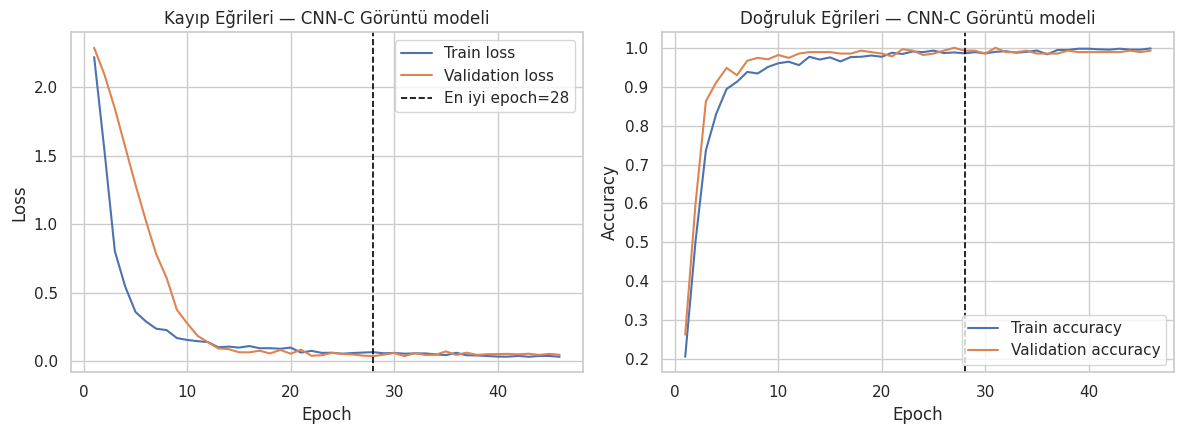

In [13]:
# Şekil 4 — seçilen sinir ağının eğitim eğrileri
epochs = np.arange(1, len(best_history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(epochs, best_history["loss"], label="Train loss")
axes[0].plot(epochs, best_history["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch, color="black", ls="--", lw=1.2, label=f"En iyi epoch={best_epoch}")
axes[0].set(title=f"Kayıp Eğrileri — {best_neural_name}", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(epochs, best_history["accuracy"], label="Train accuracy")
axes[1].plot(epochs, best_history["val_accuracy"], label="Validation accuracy")
axes[1].axvline(best_epoch, color="black", ls="--", lw=1.2)
axes[1].set(title=f"Doğruluk Eğrileri — {best_neural_name}", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_4_neural_learning_curves.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 7. Validation ile Final Model Seçimi

,Model,Aile,CV_Best_Macro_F1,Train_Accuracy,Validation_Accuracy,Validation_Macro_F1,Validation_Weighted_F1,Validation_Macro_Precision,Validation_Macro_Recall,Validation_Macro_ROC_AUC,Train_Val_Gap,Complexity
0,CNN (CNN-C Görüntü modeli),Derin Öğrenme,NaN,1.0000,0.9926,0.9927,0.9926,0.9929,0.9927,1.0000,0.0074,33002
1,Logistic Regression,Klasik ML,0.9642,1.0000,0.9778,0.9777,0.9779,0.9780,0.9778,0.9990,0.0222,4
2,SVM (RBF),Klasik ML,0.9800,0.9984,0.9741,0.9742,0.9743,0.9754,0.9739,0.9989,0.0243,12
3,Random Forest,Klasik ML,0.9737,1.0000,0.9667,0.9661,0.9664,0.9669,0.9664,0.9989,0.0333,16
4,KNN,Klasik ML,0.9687,1.0000,0.9630,0.9625,0.9626,0.9636,0.9628,0.9917,0.0370,20
5,Gradient Boosting,Klasik ML,0.9689,1.0000,0.9519,0.9512,0.9514,0.9526,0.9514,0.9983,0.0481,16


Test açılmadan validation ile seçilen final model: CNN (CNN-C Görüntü modeli)


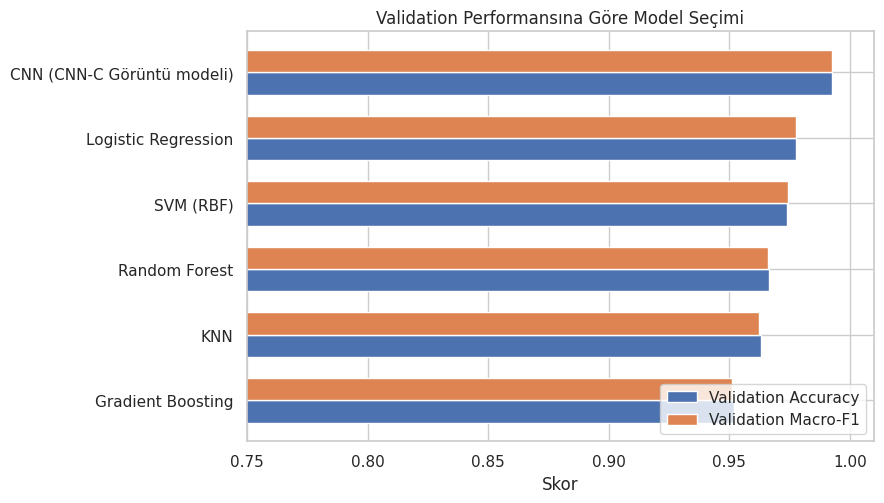

In [14]:
selection_table = pd.DataFrame(selection_rows).sort_values(
    ["Validation_Macro_F1", "Validation_Macro_ROC_AUC", "Model"],
    ascending=[False, False, True], kind="mergesort"
).reset_index(drop=True)
selection_table.to_csv(OUTPUT_DIR/"table_5_validation_model_selection.csv", index=False)
display(selection_table.round(4))

selected_model_name = selection_table.loc[0, "Model"]
print("Test açılmadan validation ile seçilen final model:", selected_model_name)

plot_df = selection_table.sort_values("Validation_Macro_F1")
fig, ax = plt.subplots(figsize=(9, 5.2))
ypos = np.arange(len(plot_df))
ax.barh(ypos-0.17, plot_df["Validation_Accuracy"], height=0.34, label="Validation Accuracy")
ax.barh(ypos+0.17, plot_df["Validation_Macro_F1"], height=0.34, label="Validation Macro-F1")
ax.set_yticks(ypos, plot_df["Model"])
ax.set_xlim(0.75, 1.01)
ax.set(title="Validation Performansına Göre Model Seçimi", xlabel="Skor")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_5_validation_comparison.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 8. Bağımsız Test Değerlendirmesi

Test kümesi ancak bütün hiperparametre ve model seçimi kararları tamamlandıktan sonra açılır. Bütün modellerin test sonuçları şeffaf karşılaştırma amacıyla raporlanır; validation ile önceden verilen seçim kararı değiştirilmez.

In [15]:
test_rows, test_predictions, test_probabilities = [], {}, {}

for name, model in classic_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)
    test_predictions[name], test_probabilities[name] = pred, prob
    test_rows.append({
        "Model": name,
        "Test_Accuracy": accuracy_score(y_test, pred),
        "Test_Macro_F1": f1_score(y_test, pred, average="macro"),
        "Test_Weighted_F1": f1_score(y_test, pred, average="weighted"),
        "Test_Macro_Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Test_Macro_Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Test_Macro_ROC_AUC": multiclass_auc(y_test, prob)
    })

neural_full_name = f"{best_neural_type} ({best_neural_name})"
prob_test_nn = best_neural.predict(test_input, verbose=0)
pred_test_nn = prob_test_nn.argmax(axis=1)
test_predictions[neural_full_name], test_probabilities[neural_full_name] = pred_test_nn, prob_test_nn
test_rows.append({
    "Model": neural_full_name,
    "Test_Accuracy": accuracy_score(y_test, pred_test_nn),
    "Test_Macro_F1": f1_score(y_test, pred_test_nn, average="macro"),
    "Test_Weighted_F1": f1_score(y_test, pred_test_nn, average="weighted"),
    "Test_Macro_Precision": precision_score(y_test, pred_test_nn, average="macro", zero_division=0),
    "Test_Macro_Recall": recall_score(y_test, pred_test_nn, average="macro", zero_division=0),
    "Test_Macro_ROC_AUC": multiclass_auc(y_test, prob_test_nn)
})

test_table = pd.DataFrame(test_rows)
final_table = selection_table.drop(columns=["Complexity"]).merge(test_table, on="Model", how="left")
final_table.insert(0, "Validation_Selected", final_table["Model"].eq(selected_model_name))
final_table.to_csv(OUTPUT_DIR/"table_6_final_performance.csv", index=False)
display(final_table.round(4))

selected_row = final_table.loc[final_table["Validation_Selected"]].iloc[0]
print("\nValidation ile seçilen model:", selected_model_name)
print(f"Final Test Accuracy={selected_row['Test_Accuracy']:.4f} | "
      f"Macro-F1={selected_row['Test_Macro_F1']:.4f} | "
      f"Macro ROC-AUC={selected_row['Test_Macro_ROC_AUC']:.4f}")
print("\nSınıflandırma raporu:")
print(classification_report(y_test, test_predictions[selected_model_name],
                            target_names=class_names, digits=4))

,Validation_Selected,Model,Aile,CV_Best_Macro_F1,Train_Accuracy,Validation_Accuracy,Validation_Macro_F1,Validation_Weighted_F1,Validation_Macro_Precision,Validation_Macro_Recall,Validation_Macro_ROC_AUC,Train_Val_Gap,Test_Accuracy,Test_Macro_F1,Test_Weighted_F1,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_ROC_AUC
0,True,CNN (CNN-C Görüntü modeli),Derin Öğrenme,NaN,1.0000,0.9926,0.9927,0.9926,0.9929,0.9927,1.0000,0.0074,0.9815,0.9812,0.9814,0.9820,0.9812,0.9999
1,False,Logistic Regression,Klasik ML,0.9642,1.0000,0.9778,0.9777,0.9779,0.9780,0.9778,0.9990,0.0222,0.9852,0.9852,0.9852,0.9854,0.9850,0.9993
2,False,SVM (RBF),Klasik ML,0.9800,0.9984,0.9741,0.9742,0.9743,0.9754,0.9739,0.9989,0.0243,0.9889,0.9888,0.9889,0.9898,0.9886,0.9999
3,False,Random Forest,Klasik ML,0.9737,1.0000,0.9667,0.9661,0.9664,0.9669,0.9664,0.9989,0.0333,0.9741,0.9738,0.9739,0.9753,0.9736,0.9993
4,False,KNN,Klasik ML,0.9687,1.0000,0.9630,0.9625,0.9626,0.9636,0.9628,0.9917,0.0370,0.9815,0.9815,0.9815,0.9823,0.9813,0.9957
5,False,Gradient Boosting,Klasik ML,0.9689,1.0000,0.9519,0.9512,0.9514,0.9526,0.9514,0.9983,0.0481,0.9630,0.9627,0.9629,0.9634,0.9625,0.9980



Validation ile seçilen model: CNN (CNN-C Görüntü modeli)
Final Test Accuracy=0.9815 | Macro-F1=0.9812 | Macro ROC-AUC=0.9999

Sınıflandırma raporu:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        27
           1     1.0000    0.9643    0.9818        28
           2     0.9615    0.9615    0.9615        26
           3     0.9655    1.0000    0.9825        28
           4     1.0000    1.0000    1.0000        27
           5     0.9643    1.0000    0.9818        27
           6     1.0000    0.9630    0.9811        27
           7     0.9643    1.0000    0.9818        27
           8     1.0000    0.9231    0.9600        26
           9     0.9643    1.0000    0.9818        27

    accuracy                         0.9815       270
   macro avg     0.9820    0.9812    0.9812       270
weighted avg     0.9820    0.9815    0.9814       270



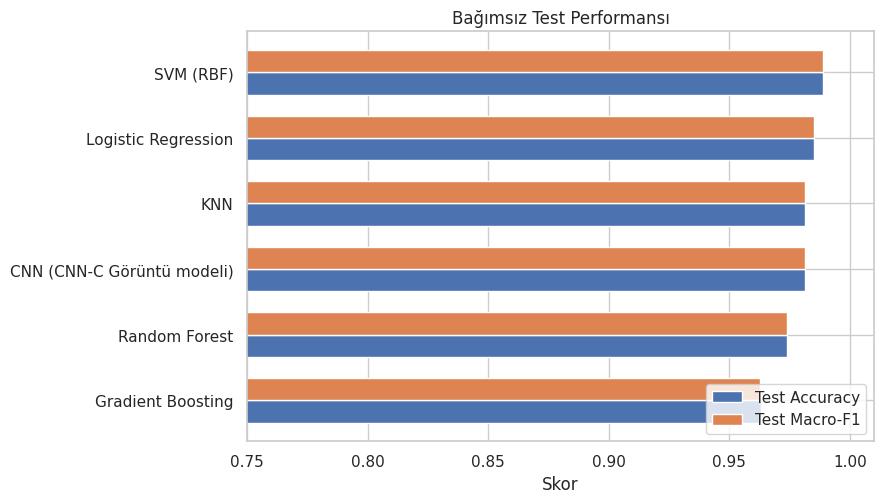

In [16]:
# Şekil 6 — test performansı
plot_df = test_table.sort_values("Test_Macro_F1")
fig, ax = plt.subplots(figsize=(9, 5.2))
ypos = np.arange(len(plot_df))
ax.barh(ypos-0.17, plot_df["Test_Accuracy"], height=0.34, label="Test Accuracy")
ax.barh(ypos+0.17, plot_df["Test_Macro_F1"], height=0.34, label="Test Macro-F1")
ax.set_yticks(ypos, plot_df["Model"])
ax.set_xlim(0.75, 1.01)
ax.set(title="Bağımsız Test Performansı", xlabel="Skor")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_6_test_comparison.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

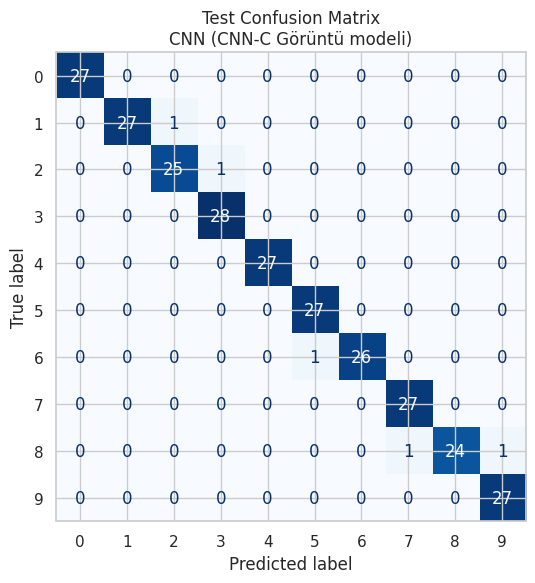

In [17]:
# Şekil 7 — validation ile seçilen modelin confusion matrix'i
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, test_predictions[selected_model_name])
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test Confusion Matrix\n{selected_model_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_7_confusion_matrix.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

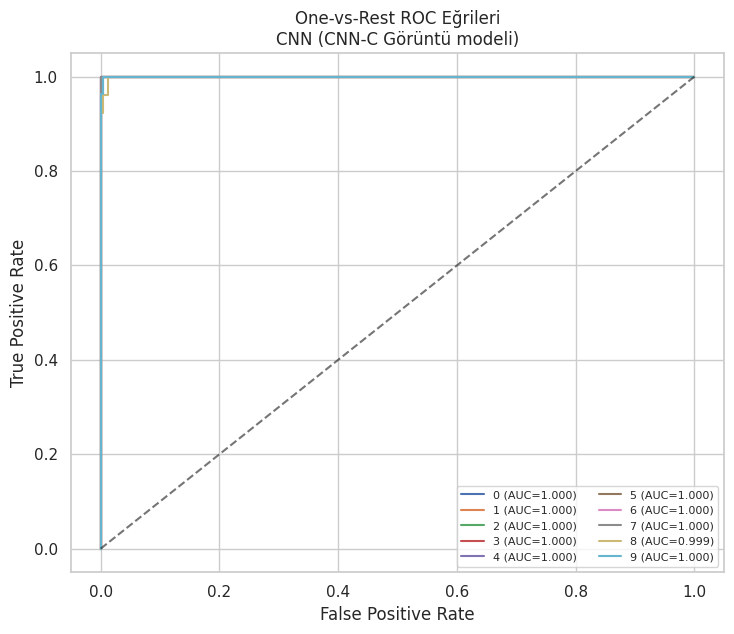

In [18]:
# Şekil 8 — seçilen model için sınıf-bazlı One-vs-Rest ROC eğrileri
selected_prob = test_probabilities[selected_model_name]
y_test_bin = label_binarize(y_test, classes=np.arange(10))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for digit in range(10):
    fpr, tpr, _ = roc_curve(y_test_bin[:, digit], selected_prob[:, digit])
    ax.plot(fpr, tpr, lw=1.5, label=f"{digit} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=.6)
ax.set(title=f"One-vs-Rest ROC Eğrileri\n{selected_model_name}",
       xlabel="False Positive Rate", ylabel="True Positive Rate")
ax.legend(ncol=2, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_8_multiclass_roc.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 9. İstatistiksel Belirsizlik ve Eşleştirilmiş Model Karşılaştırması

Tek bir test bölünmesindeki küçük skor farklarının aşırı yorumlanmaması için iki ek analiz uygulanır:

1. **Bootstrap %95 güven aralıkları:** Aynı 270 test örneği 2.000 kez yerine koymalı örneklenerek doğruluk ve Macro-F1 belirsizliği tahmin edilir.
2. **Exact McNemar testi:** Validation ile seçilen CNN-C ile testte sayısal olarak en yüksek skoru veren RBF-SVM, aynı test örneklerindeki doğru/yanlış kararları üzerinden eşleştirilmiş olarak karşılaştırılır.

Bu analizler model seçim kuralını değiştirmez; yalnızca testte görülen küçük farkın istatistiksel belirsizliğini açıklar.


,Model,Test_Accuracy,Accuracy_CI_2.5,Accuracy_CI_97.5,Test_Macro_F1,Macro_F1_CI_2.5,Macro_F1_CI_97.5
3,SVM (RBF),0.98889,0.97407,1.00000,0.98885,0.97424,1.00000
0,Logistic Regression,0.98519,0.97037,0.99630,0.98516,0.96917,0.99664
1,KNN,0.98148,0.96296,0.99630,0.98146,0.96293,0.99614
5,CNN (CNN-C Görüntü modeli),0.98148,0.96296,0.99630,0.98124,0.96239,0.99614
2,Random Forest,0.97407,0.95556,0.99259,0.97379,0.95194,0.99163
4,Gradient Boosting,0.96296,0.94074,0.98519,0.96271,0.93787,0.98293


,Karsilastirma,CNN_yanlis_SVM_dogru,CNN_dogru_SVM_yanlis,McNemar_exact_p,Accuracy_farki_SVM_eksi_CNN,Accuracy_farki_bootstrap_CI_2.5,Accuracy_farki_bootstrap_CI_97.5,Macro_F1_farki_SVM_eksi_CNN,Macro_F1_farki_bootstrap_CI_2.5,Macro_F1_farki_bootstrap_CI_97.5
0,RBF-SVM - CNN-C,4,2,0.6875,0.00741,-0.01111,0.02593,0.00761,-0.0098,0.02622


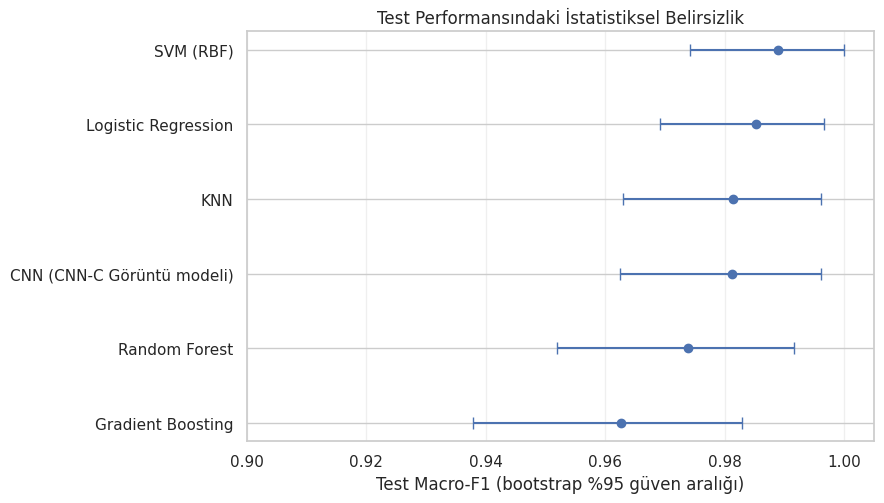

McNemar: CNN yanlış/SVM doğru=4, CNN doğru/SVM yanlış=2, exact p=0.688
Yorum: p-değeri küçük değildir; bu test bölünmesinde SVM-CNN farkını istatistiksel olarak ayırt eden kanıt yoktur.


In [19]:
from scipy.stats import binomtest

# 2.000 ortak bootstrap yeniden örnekleme: tüm modeller aynı indekslerle değerlendirilir.
BOOTSTRAP_B = 2000
rng_boot = np.random.default_rng(SEED)
boot_indices = rng_boot.integers(0, len(y_test), size=(BOOTSTRAP_B, len(y_test)))

bootstrap_rows = []
for name, pred in test_predictions.items():
    acc_samples = (pred[boot_indices] == y_test[boot_indices]).mean(axis=1)
    f1_samples = np.array([
        f1_score(y_test[ii], pred[ii], average="macro", labels=np.arange(10), zero_division=0)
        for ii in boot_indices
    ])
    bootstrap_rows.append({
        "Model": name,
        "Test_Accuracy": accuracy_score(y_test, pred),
        "Accuracy_CI_2.5": np.percentile(acc_samples, 2.5),
        "Accuracy_CI_97.5": np.percentile(acc_samples, 97.5),
        "Test_Macro_F1": f1_score(y_test, pred, average="macro"),
        "Macro_F1_CI_2.5": np.percentile(f1_samples, 2.5),
        "Macro_F1_CI_97.5": np.percentile(f1_samples, 97.5),
    })

bootstrap_table = pd.DataFrame(bootstrap_rows).sort_values("Test_Macro_F1", ascending=False)
bootstrap_table.to_csv(OUTPUT_DIR/"table_8_bootstrap_confidence_intervals.csv", index=False)
display(bootstrap_table.round(5))

# CNN-C ve RBF-SVM için eşleştirilmiş Exact McNemar testi.
cnn_name = "CNN-C Görüntü modeli"
svm_name = "SVM (RBF)"
if best_neural_name == cnn_name:
    cnn_pred = pred_test_nn
else:
    # Ana deneyin validasyonla seçilen modelini değiştirmiyoruz; CNN-C'yi sadece bu karşılaştırma için ölçüyoruz.
    cnn_predict = neural_models[cnn_name].predict(img_test_cnn, verbose=0)
    cnn_pred = cnn_predict.argmax(axis=1)
svm_pred = test_predictions[svm_name]
cnn_wrong_svm_right = int(np.sum((cnn_pred != y_test) & (svm_pred == y_test)))
cnn_right_svm_wrong = int(np.sum((cnn_pred == y_test) & (svm_pred != y_test)))
mcnemar_p = binomtest(
    cnn_wrong_svm_right,
    cnn_wrong_svm_right + cnn_right_svm_wrong,
    p=0.5, alternative="two-sided"
).pvalue

svm_acc_boot = (svm_pred[boot_indices] == y_test[boot_indices]).mean(axis=1)
cnn_acc_boot = (cnn_pred[boot_indices] == y_test[boot_indices]).mean(axis=1)
svm_f1_boot = np.array([f1_score(y_test[ii], svm_pred[ii], average="macro", labels=np.arange(10), zero_division=0) for ii in boot_indices])
cnn_f1_boot = np.array([f1_score(y_test[ii], cnn_pred[ii], average="macro", labels=np.arange(10), zero_division=0) for ii in boot_indices])

paired_table = pd.DataFrame([{
    "Karsilastirma": "RBF-SVM - CNN-C",
    "CNN_yanlis_SVM_dogru": cnn_wrong_svm_right,
    "CNN_dogru_SVM_yanlis": cnn_right_svm_wrong,
    "McNemar_exact_p": mcnemar_p,
    "Accuracy_farki_SVM_eksi_CNN": accuracy_score(y_test, svm_pred) - accuracy_score(y_test, cnn_pred),
    "Accuracy_farki_bootstrap_CI_2.5": np.percentile(svm_acc_boot - cnn_acc_boot, 2.5),
    "Accuracy_farki_bootstrap_CI_97.5": np.percentile(svm_acc_boot - cnn_acc_boot, 97.5),
    "Macro_F1_farki_SVM_eksi_CNN": f1_score(y_test, svm_pred, average="macro") - f1_score(y_test, cnn_pred, average="macro"),
    "Macro_F1_farki_bootstrap_CI_2.5": np.percentile(svm_f1_boot - cnn_f1_boot, 2.5),
    "Macro_F1_farki_bootstrap_CI_97.5": np.percentile(svm_f1_boot - cnn_f1_boot, 97.5),
}])
paired_table.to_csv(OUTPUT_DIR/"table_9_paired_cnn_svm_comparison.csv", index=False)
display(paired_table.round(5))

# Sınıf-bazlı CNN-C / RBF-SVM karşılaştırması.
per_class_rows = []
for digit in range(10):
    for name, pred in [("CNN-C", cnn_pred), ("RBF-SVM", svm_pred)]:
        p_, r_, f_, s_ = precision_recall_fscore_support(
            y_test, pred, labels=[digit], zero_division=0
        )
        per_class_rows.append({
            "Sinif": digit, "Model": name, "Precision": p_[0],
            "Recall": r_[0], "F1": f_[0], "Support": int(s_[0])
        })
per_class_table = pd.DataFrame(per_class_rows)
per_class_table.to_csv(OUTPUT_DIR/"table_10_per_class_cnn_svm.csv", index=False)

# Şekil 9 — test Macro-F1 için bootstrap %95 güven aralıkları.
plot_ci = bootstrap_table.iloc[::-1].reset_index(drop=True)
ypos = np.arange(len(plot_ci))
vals = plot_ci["Test_Macro_F1"].to_numpy()
lo = vals - plot_ci["Macro_F1_CI_2.5"].to_numpy()
hi = plot_ci["Macro_F1_CI_97.5"].to_numpy() - vals
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.errorbar(vals, ypos, xerr=np.vstack([lo, hi]), fmt="o", capsize=4)
ax.set_yticks(ypos, plot_ci["Model"])
ax.set_xlim(0.90, 1.005)
ax.set_xlabel("Test Macro-F1 (bootstrap %95 güven aralığı)")
ax.set_title("Test Performansındaki İstatistiksel Belirsizlik")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"figure_9_bootstrap_confidence_intervals.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

print(f"McNemar: CNN yanlış/SVM doğru={cnn_wrong_svm_right}, CNN doğru/SVM yanlış={cnn_right_svm_wrong}, exact p={mcnemar_p:.3f}")
print("Yorum: p-değeri küçük değildir; bu test bölünmesinde SVM-CNN farkını istatistiksel olarak ayırt eden kanıt yoktur.")


## 10. Overfitting / Genelleme Analizi

In [20]:
overfit_table = selection_table[[
    "Model", "Aile", "Train_Accuracy", "Validation_Accuracy",
    "Train_Val_Gap", "Validation_Macro_F1", "Validation_Macro_ROC_AUC"
]].copy().sort_values("Train_Val_Gap", ascending=False)
overfit_table["Yorum"] = np.select(
    [overfit_table["Train_Val_Gap"] > 0.05, overfit_table["Train_Val_Gap"] > 0.02],
    ["Belirgin overfitting riski", "Hafif overfitting işareti"],
    default="Genelleme farkı düşük"
)
overfit_table.to_csv(OUTPUT_DIR/"table_7_overfitting_analysis.csv", index=False)
display(overfit_table.round(4))

,Model,Aile,Train_Accuracy,Validation_Accuracy,Train_Val_Gap,Validation_Macro_F1,Validation_Macro_ROC_AUC,Yorum
5,Gradient Boosting,Klasik ML,1.0000,0.9519,0.0481,0.9512,0.9983,Hafif overfitting işareti
4,KNN,Klasik ML,1.0000,0.9630,0.0370,0.9625,0.9917,Hafif overfitting işareti
3,Random Forest,Klasik ML,1.0000,0.9667,0.0333,0.9661,0.9989,Hafif overfitting işareti
2,SVM (RBF),Klasik ML,0.9984,0.9741,0.0243,0.9742,0.9989,Hafif overfitting işareti
1,Logistic Regression,Klasik ML,1.0000,0.9778,0.0222,0.9777,0.9990,Hafif overfitting işareti
0,CNN (CNN-C Görüntü modeli),Derin Öğrenme,1.0000,0.9926,0.0074,0.9927,1.0000,Genelleme farkı düşük


## 11. Modelleri ve Çalıştırma Özetini Kaydetme

In [21]:
for name, model in classic_models.items():
    safe = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(model, OUTPUT_DIR/f"model_{safe}.joblib")
best_neural.save(OUTPUT_DIR/"model_best_neural.keras")

run_summary = {
    "student": "Reyhan Onbaşı",
    "seed": SEED,
    "dataset": "scikit-learn Digits",
    "dataset_size": int(len(y)),
    "selected_model_by_validation": selected_model_name,
    "selected_neural_model": best_neural_name,
    "selected_neural_best_epoch": best_epoch,
    "test_was_not_used_for_selection": True,
    "primary_metric": "Macro F1",
    "dataset_url": "https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html",
    "original_dataset_url": "https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits"
}
with open(OUTPUT_DIR/"run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, ensure_ascii=False, indent=2)

print("Kaydedilen çıktı sayısı:", len(list(OUTPUT_DIR.iterdir())))
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Kaydedilen çıktı sayısı: 26
- figure_1_class_distribution.png
- figure_2_sample_images.png
- figure_3_mean_pixel_heatmap.png
- figure_4_neural_learning_curves.png
- figure_5_validation_comparison.png
- figure_6_test_comparison.png
- figure_7_confusion_matrix.png
- figure_8_multiclass_roc.png
- figure_9_bootstrap_confidence_intervals.png
- model_best_neural.keras
- model_gradient_boosting.joblib
- model_knn.joblib
- model_logistic_regression.joblib
- model_random_forest.joblib
- model_svm_rbf.joblib
- run_summary.json
- table_10_per_class_cnn_svm.csv
- table_1_dataset_summary.csv
- table_2_data_split.csv
- table_3_classic_tuning.csv
- table_4_neural_experiments.csv
- table_5_validation_model_selection.csv
- table_6_final_performance.csv
- table_7_overfitting_analysis.csv
- table_8_bootstrap_confidence_intervals.csv
- table_9_paired_cnn_svm_comparison.csv


### Ana deney ek kayıtları

Veri ayrımının **örnek indeksleri** ve her modelin test tahminleri saklanır. Bu kayıtlar, sonradan karşılaştırmaların yeniden hesaplanabilmesini sağlar. CNN-C ayrıca ayrı model olarak da kaydedilir (ana deneydeki CNN başlangıç tohumu `44`).

In [22]:
import hashlib
np.savez_compressed(OUTPUT_ROOT / "split_indices.npz", train=idx_train, validation=idx_val, test=idx_test)

versions = {name: importlib.metadata.version(name) for name in
            ("tensorflow", "keras", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn")}
versions.update({"python": platform.python_version(), "platform": platform.platform(),
                 "tensorflow_devices": [str(d) for d in tf.config.list_physical_devices()],
                 "run_id": RUN_ID})
(OUTPUT_ROOT / "environment.json").write_text(
    json.dumps(versions, ensure_ascii=False, indent=2), encoding="utf-8")

for name, pred in test_predictions.items():
    key = "".join(ch if ch.isalnum() else "_" for ch in name).strip("_")
    pd.DataFrame({"sample_index": idx_test, "true_label": y_test,
                  "prediction": pred}).to_csv(OUTPUT_DIR / f"test_predictions_{key}.csv", index=False)

if best_neural_name != "CNN-C Görüntü modeli":
    pd.DataFrame({"sample_index": idx_test, "true_label": y_test,
                  "prediction": cnn_pred}).to_csv(OUTPUT_DIR / "test_predictions_CNN_C.csv", index=False)

for config_name, hist in neural_histories.items():
    tag = "".join(ch if ch.isalnum() else "_" for ch in config_name).strip("_")
    (OUTPUT_DIR / f"history_{tag}.json").write_text(
        json.dumps({k: [float(v) for v in arr] for k, arr in hist.items()}, indent=2), encoding="utf-8")

# Üç sinir ağının tamamını kayıt altına al (sadece seçilen ağ değil).
NEURAL_MODEL_FILES = {
    "MLP-A Kompakt": "model_mlp_a_kompakt.keras",
    "MLP-B Geniş": "model_mlp_b_genis.keras",
    "CNN-C Görüntü modeli": "model_cnn_c_goruntu.keras",
}
for config_name, filename in NEURAL_MODEL_FILES.items():
    neural_models[config_name].save(OUTPUT_DIR / filename)
(OUTPUT_DIR / "neural_configurations.json").write_text(
    json.dumps(neural_configs, ensure_ascii=False, indent=2), encoding="utf-8")

cnn_main = neural_models["CNN-C Görüntü modeli"]
assert cnn_main.count_params() == 33002
cnn_main.save(OUTPUT_DIR / "model_cnn_c_ana_deney_seed44.keras")
(OUTPUT_DIR / "cnn_c_architecture.json").write_text(cnn_main.to_json(), encoding="utf-8")
print("Ana deney kaydedildi. Test modeli seçimi değiştirilmedi.")

import hashlib
split_hash = hashlib.sha256(np.concatenate([idx_train, idx_val, idx_test]).astype(np.int64).tobytes()).hexdigest()
(OUTPUT_ROOT / "split_sha256.txt").write_text(split_hash + "\n", encoding="utf-8")
(OUTPUT_ROOT / "calisma_ilkeleri.json").write_text(json.dumps({
    "run_id": RUN_ID,
    "data_split_seed": SEED,
    "main_neural_seeds": {cfg["Config"]: SEED + i for i, cfg in enumerate(neural_configs)},
    "stability_seeds": [101, 202, 303, 404, 505],
    "extra_validation_seeds": [101, 202, 303],
    "same_split_for_all_sections": True,
    "test_not_used_to_select_primary_model": True,
    "stability_seed_selection_by_test": False,
    "extra_validation_uses_test": False,
    "previous_mac_outputs_modified": False,
    "github_modified": False,
}, indent=2, ensure_ascii=False), encoding="utf-8")

for name, pred in test_predictions.items():
    match = final_table.loc[final_table["Model"].eq(name), "Test_Accuracy"]
    assert len(match) == 1 and np.isclose(accuracy_score(y_test, pred), float(match.iloc[0]))
print("Ana deneyin test tahminleri ile sonuç tablosu uyumlu.")

Ana deney kaydedildi. Test modeli seçimi değiştirilmedi.
Ana deneyin test tahminleri ile sonuç tablosu uyumlu.


In [23]:
from shutil import make_archive
ara_ana = make_archive(str(Path('/content') / f'YSA_F26_ANA_YEDEK_{RUN_ID}' if Path('/content').exists() else f'YSA_F26_ANA_YEDEK_{RUN_ID}'), 'zip', root_dir=OUTPUT_ROOT)
print('Ana deney ara yedeği oluşturuldu:', ara_ana)
print('Colab Dosyalar panelinden isteğe bağlı indirilebilir. Tam deney devam ediyor.')

Ana deney ara yedeği oluşturuldu: /content/YSA_F26_ANA_YEDEK_20261017T160921Z.zip
Colab Dosyalar panelinden isteğe bağlı indirilebilir. Tam deney devam ediyor.


## Bölüm B — CNN-C kararlılık analizi (5 seed)

Aynı veri ayrımında CNN-C mimarisi (33.002 parametre) beş kez yeniden eğitilir: **101, 202, 303, 404, 505**. Her koşunun checkpoint'i, eğitim geçmişi, doğrulama ve test tahminleri ayrı saklanır. **Önce bütün eğitimler tamamlanır, sonra test değerlendirmeleri yapılır.** Teste bakarak en iyi seed seçilmez. Bu analiz sadece başlangıç tohumuna duyarlılığı gösterir.

In [24]:
STABILITY_SEEDS = [101, 202, 303, 404, 505]
STABILITY_DIR = OUTPUT_ROOT / "kararlilik"
STABILITY_DIR.mkdir(parents=True, exist_ok=True)
STABILITY_PLAN = {
    "seeds": STABILITY_SEEDS, "architecture": "CNN-C (33002 parameters)",
    "data_split": "Same stratified train/val/test as main; seed=42", "max_epochs": 250,
    "batch_size": 32, "dropout": 0.3, "l2": 0.0001, "learning_rate": 0.001,
    "checkpoint": "minimum validation loss", "early_stopping_patience": 18,
    "reduce_lr_patience": 7, "test_policy": "evaluate only after all five trainings; no seed selection"
}
(STABILITY_DIR / "experiment_plan.json").write_text(json.dumps(STABILITY_PLAN, indent=2), encoding="utf-8")

class EveryTenEpochs(tf.keras.callbacks.Callback):
    def __init__(self, seed):
        super().__init__()
        self.seed = seed
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"  Seed {self.seed}: epoch {epoch+1}, val_loss={logs.get('val_loss', float('nan')):.5f}, val_accuracy={logs.get('val_accuracy', float('nan')):.4f}")

stability_train_rows=[]
for seq, seed in enumerate(STABILITY_SEEDS, start=1):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(seed)
    model = build_cnn(dropout=0.30, l2_value=1e-4, learning_rate=1e-3)
    assert model.count_params() == 33002
    checkpoint = STABILITY_DIR / f"cnn_seed_{seed}.keras"
    cb = [
        callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min", save_best_only=True),
        callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=18,
                                min_delta=1e-4, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", patience=7,
                                    factor=0.5, min_lr=1e-6),
        EveryTenEpochs(seed),
    ]
    print(f"[{seq}/5] Eğitiliyor: seed={seed}")
    fit = model.fit(img_train_cnn, y_train, validation_data=(img_val_cnn, y_val),
                    batch_size=32, epochs=250, callbacks=cb, verbose=0, shuffle=True)
    hist = {k: [float(t) for t in vals] for k, vals in fit.history.items()}
    (STABILITY_DIR / f"history_seed_{seed}.json").write_text(json.dumps(hist), encoding="utf-8")
    del model
    tf.keras.backend.clear_session()
    best = models.load_model(checkpoint)
    val_prob = best.predict(img_val_cnn, verbose=0)
    val_pred = val_prob.argmax(axis=1)
    stability_train_rows.append({
        "seed": seed, "epochs_run": len(hist["loss"]),
        "best_epoch": int(np.argmin(hist["val_loss"]) + 1),
        "min_val_loss": float(np.min(hist["val_loss"])),
        "validation_accuracy": accuracy_score(y_val, val_pred),
        "validation_macro_f1": f1_score(y_val, val_pred, average="macro")
    })
    pd.DataFrame({"sample_index": idx_val, "true_label": y_val,
                  "prediction": val_pred}).to_csv(
                      STABILITY_DIR / f"validation_predictions_seed_{seed}.csv", index=False)
    pd.DataFrame(stability_train_rows).to_csv(STABILITY_DIR / "training_runs.csv", index=False)
    print(f"  Seed {seed} bitti — val accuracy %{100*accuracy_score(y_val, val_pred):.2f}")
    del best
    tf.keras.backend.clear_session()
    gc.collect()

assert len(stability_train_rows) == 5
print("Beş eğitim tamamlandı. Artık aynı test kümesinde değerlendirme yapılabilir.")

[1/5] Eğitiliyor: seed=101
  Seed 101: epoch 1, val_loss=2.28840, val_accuracy=0.3333
  Seed 101: epoch 10, val_loss=0.31998, val_accuracy=0.9630
  Seed 101: epoch 20, val_loss=0.06152, val_accuracy=0.9852
  Seed 101: epoch 30, val_loss=0.06863, val_accuracy=0.9815
  Seed 101: epoch 40, val_loss=0.05379, val_accuracy=0.9889
  Seed 101: epoch 50, val_loss=0.06891, val_accuracy=0.9815
  Seed 101: epoch 60, val_loss=0.04883, val_accuracy=0.9889
  Seed 101 bitti — val accuracy %99.26
[2/5] Eğitiliyor: seed=202
  Seed 202: epoch 1, val_loss=2.29446, val_accuracy=0.2593
  Seed 202: epoch 10, val_loss=0.30897, val_accuracy=0.9741
  Seed 202: epoch 20, val_loss=0.06742, val_accuracy=0.9889
  Seed 202: epoch 30, val_loss=0.08672, val_accuracy=0.9815
  Seed 202: epoch 40, val_loss=0.05076, val_accuracy=0.9889
  Seed 202: epoch 50, val_loss=0.06590, val_accuracy=0.9852
  Seed 202 bitti — val accuracy %99.63
[3/5] Eğitiliyor: seed=303
  Seed 303: epoch 1, val_loss=2.28811, val_accuracy=0.2778
  Se

  Test seed 101: 265/270 (%98.15)
  Test seed 202: 269/270 (%99.63)
  Test seed 303: 262/270 (%97.04)
  Test seed 404: 269/270 (%99.63)
  Test seed 505: 268/270 (%99.26)


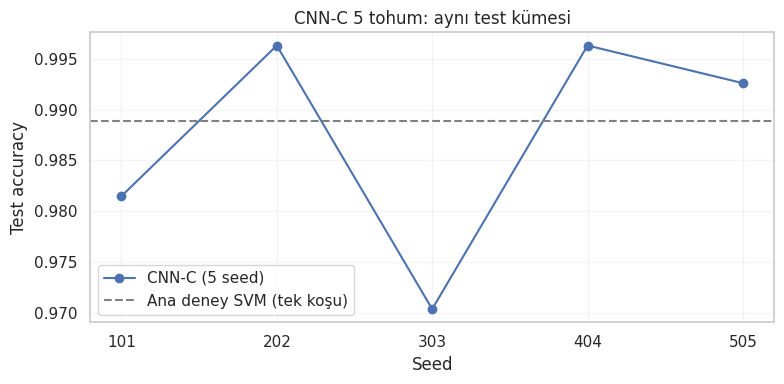

,seed,epochs_run,best_epoch,min_val_loss,validation_accuracy,validation_macro_f1,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall,test_macro_auc,correct,errors
0,101,62,44,0.04231,0.99259,0.99259,0.98148,0.98184,0.98305,0.98160,0.99996,265,5
1,202,55,37,0.04943,0.99630,0.99636,0.99630,0.99630,0.99630,0.99643,1.00000,269,1
2,303,49,31,0.05623,0.98889,0.98894,0.97037,0.96928,0.97177,0.96965,0.99994,262,8
3,404,41,23,0.06269,0.98889,0.98879,0.99630,0.99628,0.99655,0.99615,0.99997,269,1
4,505,68,50,0.05175,0.98889,0.98888,0.99259,0.99236,0.99286,0.99231,1.00000,268,2


,metric,mean,std,min,max
0,validation_accuracy,0.99111,0.00331,0.98889,0.99630
1,validation_macro_f1,0.99111,0.00335,0.98879,0.99636
2,test_accuracy,0.98741,0.01129,0.97037,0.99630
3,test_macro_f1,0.98721,0.01164,0.96928,0.99630
4,test_macro_precision,0.98810,0.01065,0.97177,0.99655
5,test_macro_recall,0.98723,0.01152,0.96965,0.99643
6,test_macro_auc,0.99997,0.00003,0.99994,1.00000


Ortalama test doğruluğu: 98.741 %
Bu beş koşu bağımsız test setleri değildir; aynı sabit test bölmesi kullanılır.


In [25]:
from sklearn.metrics import cohen_kappa_score

stability_test_rows=[]
stability_per_class=[]
stability_all_preds=[]
for seed in STABILITY_SEEDS:
    tf.keras.backend.clear_session()
    saved = models.load_model(STABILITY_DIR / f"cnn_seed_{seed}.keras")
    probabilities = saved.predict(img_test_cnn, verbose=0)
    assert probabilities.shape == (270, 10) and np.isfinite(probabilities).all()
    pred = probabilities.argmax(axis=1)
    np.save(STABILITY_DIR / f"test_probabilities_seed_{seed}.npy", probabilities)
    pd.DataFrame({"sample_index": idx_test, "true_label": y_test,
                  "prediction": pred}).to_csv(
                      STABILITY_DIR / f"test_predictions_seed_{seed}.csv", index=False)
    row = {"seed": seed,
           "test_accuracy": accuracy_score(y_test, pred),
           "test_macro_f1": f1_score(y_test, pred, average="macro"),
           "test_macro_precision": precision_score(y_test, pred, average="macro", zero_division=0),
           "test_macro_recall": recall_score(y_test, pred, average="macro", zero_division=0),
           "test_macro_auc": roc_auc_score(y_test, probabilities, multi_class="ovr", average="macro"),
           "correct": int(np.sum(pred == y_test)), "errors": int(np.sum(pred != y_test))}
    assert row["correct"] + row["errors"] == len(y_test)
    stability_test_rows.append(row)
    p, r, f, support = precision_recall_fscore_support(
        y_test, pred, labels=list(range(10)), zero_division=0)
    for cls in range(10):
        stability_per_class.append({"seed": seed, "class": cls, "precision": p[cls],
                                    "recall": r[cls], "f1": f[cls], "support": int(support[cls])})
    np.savetxt(STABILITY_DIR / f"confusion_matrix_seed_{seed}.csv",
               confusion_matrix(y_test, pred), fmt="%d", delimiter=",")
    stability_all_preds.append(pred)
    print(f"  Test seed {seed}: {row['correct']}/270 (%{100*row['test_accuracy']:.2f})")
    del saved
    tf.keras.backend.clear_session()
    gc.collect()

stability_all = pd.DataFrame(stability_train_rows).merge(
    pd.DataFrame(stability_test_rows), on="seed", validate="one_to_one")
stability_all.to_csv(STABILITY_DIR / "all_five_runs.csv", index=False)
metric_cols = [c for c in stability_all.columns if c.startswith("test_") or c.startswith("validation_")]
stability_summary = (stability_all[metric_cols].agg(["mean", "std", "min", "max"])
                     .T.rename_axis("metric").reset_index())
stability_summary.to_csv(STABILITY_DIR / "stability_summary.csv", index=False)
pd.DataFrame(stability_per_class).to_csv(STABILITY_DIR / "per_class_metrics.csv", index=False)

arr = np.stack(stability_all_preds)
variety = np.array([len(np.unique(arr[:, i])) for i in range(len(y_test))])
consensus = np.array([np.bincount(arr[:, i], minlength=10).argmax() for i in range(len(y_test))])
pd.DataFrame({"sample_index": idx_test, "true_label": y_test,
              "correct_seed_count": (arr == y_test).sum(axis=0),
              "distinct_prediction_count": variety,
              "all_seeds_agree": variety == 1,
              "majority_prediction_descriptive_only": consensus}).to_csv(
                  STABILITY_DIR / "per_sample_stability.csv", index=False)

pairs=[]
for i, first in enumerate(STABILITY_SEEDS):
    for j in range(i+1, len(STABILITY_SEEDS)):
        second = STABILITY_SEEDS[j]
        pairs.append({"seed_1": first, "seed_2": second,
                      "prediction_agreement": float(np.mean(arr[i] == arr[j])),
                      "cohen_kappa": float(cohen_kappa_score(arr[i], arr[j]))})
pd.DataFrame(pairs).to_csv(STABILITY_DIR / "pairwise_prediction_agreement.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(stability_all["seed"].astype(str), stability_all["test_accuracy"], marker="o", label="CNN-C (5 seed)")
svm_main_score = float(test_table.loc[test_table["Model"].eq("SVM (RBF)"), "Test_Accuracy"].iloc[0])
ax.axhline(svm_main_score, linestyle="--", color="gray", label="Ana deney SVM (tek koşu)")
ax.set(xlabel="Seed", ylabel="Test accuracy", title="CNN-C 5 tohum: aynı test kümesi")
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(STABILITY_DIR / "stability_five_runs.png", dpi=300, bbox_inches="tight")
plt.show()

display(stability_all.round(5))
display(stability_summary.round(5))
print("Ortalama test doğruluğu:", round(100 * stability_all["test_accuracy"].mean(), 3), "%")
print("Bu beş koşu bağımsız test setleri değildir; aynı sabit test bölmesi kullanılır.")

In [26]:
assert len(stability_all) == 5 and set(stability_all['seed']) == set(STABILITY_SEEDS)
assert all(stability_all['correct'] + stability_all['errors'] == len(y_test))
ara_kararlilik = make_archive(str(Path('/content') / f'YSA_F26_KARARLILIK_YEDEK_{RUN_ID}' if Path('/content').exists() else f'YSA_F26_KARARLILIK_YEDEK_{RUN_ID}'), 'zip', root_dir=OUTPUT_ROOT)
print('Kararlılık dâhil ara yedek:', ara_kararlilik)
print('Son bölümdeki 9 eğitim başlıyor; test verisi bu bölümde kullanılmayacak.')

Kararlılık dâhil ara yedek: /content/YSA_F26_KARARLILIK_YEDEK_20261017T160921Z.zip
Son bölümdeki 9 eğitim başlıyor; test verisi bu bölümde kullanılmayacak.


## Bölüm C — CNN mimarisi / düzenlileştirme ek doğrulaması (3 × 3)

**Test bölümü kullanılmaz.** Referans, küçük CNN ve daha güçlü düzenlileştirme koşulları; **101, 202, 303** ortak seed değerlerinde karşılaştırılır. Bu keşifsel deney, ana deneydeki model seçiminin yerine geçmez ve aynı validation kümesi tekrar kullanıldığı için seçim yanlılığına açık olabilir.

Checkpoint ve karşılaştırma ölçütü, L2 düzenlileştirme cezasını **içermeyen** doğrulama çapraz entropisidir (`val_ce`). Farklı L2 katsayılarının toplam kayba doğrudan etkisi böylece kıyaslamaya karışmaz.

In [27]:
from sklearn.metrics import log_loss

EXTRA_SEEDS = [101, 202, 303]
EXTRA_CONFIGS = [
    {"name": "Referans", "width": 32, "dropout": 0.30, "l2": 0.0001},
    {"name": "Kucuk_CNN", "width": 16, "dropout": 0.30, "l2": 0.0001},
    {"name": "Guclu_duzenlilestirme", "width": 32, "dropout": 0.40, "l2": 0.0003},
]
EXTRA_DIR = OUTPUT_ROOT / "ek_dogrulama"
EXTRA_DIR.mkdir(parents=True, exist_ok=True)
EXTRA_PLAN = {
    "configs": EXTRA_CONFIGS, "seeds": EXTRA_SEEDS, "max_epochs": 150,
    "batch_size": 32, "learning_rate": 0.001,
    "checkpoint_metric": "val_ce (not regularized loss)",
    "selection_metric": "lowest mean validation CE; ties: fewer parameters, name",
    "test_evaluated": False, "planned_after_prior_test_review": True,
    "data_split": "Identical to main experiment"
}
(EXTRA_DIR / "experiment_plan.json").write_text(json.dumps(EXTRA_PLAN, indent=2), encoding="utf-8")

def build_variant(cfg):
    width = cfg["width"]
    reg = regularizers.l2(cfg["l2"])
    variant = models.Sequential([
        layers.Input(shape=(8, 8, 1)),
        layers.Conv2D(width, 3, padding="same", activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Conv2D(width, 3, padding="same", activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D(2),
        layers.Dropout(cfg["dropout"]),
        layers.Conv2D(2 * width, 3, padding="same", activation="relu", kernel_regularizer=reg),
        layers.GlobalAveragePooling2D(),
        layers.Dense(2 * width, activation="relu", kernel_regularizer=reg),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(10, activation="softmax")
    ])
    variant.compile(
        optimizer=optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", tf.keras.metrics.SparseCategoricalCrossentropy(name="ce")])
    return variant

extra_rows = []
for conf in EXTRA_CONFIGS:
    for seed in EXTRA_SEEDS:
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(seed)
        variant = build_variant(conf)
        tag = f"{conf['name']}_{seed}"
        checkpoint = EXTRA_DIR / f"{tag}.keras"
        cb = [
            callbacks.ModelCheckpoint(str(checkpoint), monitor="val_ce", mode="min", save_best_only=True),
            callbacks.EarlyStopping(monitor="val_ce", mode="min", patience=12, min_delta=0),
            callbacks.ReduceLROnPlateau(monitor="val_ce", mode="min", patience=5,
                                        factor=0.5, min_lr=1e-6),
            EveryTenEpochs(tag),
        ]
        print(f"Ek doğrulama: {tag}")
        fit = variant.fit(img_train_cnn, y_train, validation_data=(img_val_cnn, y_val),
                          epochs=150, batch_size=32, callbacks=cb, shuffle=True, verbose=0)
        history = {k: [float(t) for t in vals] for k, vals in fit.history.items()}
        (EXTRA_DIR / f"history_{tag}.json").write_text(json.dumps(history), encoding="utf-8")
        del variant
        tf.keras.backend.clear_session()
        saved = models.load_model(checkpoint)
        prob_tr = saved.predict(img_train_cnn, verbose=0)
        prob_va = saved.predict(img_val_cnn, verbose=0)
        tr_ce = log_loss(y_train, prob_tr, labels=list(range(10)))
        va_ce = log_loss(y_val, prob_va, labels=list(range(10)))
        best_epoch = int(np.argmin(history["val_ce"]))
        extra_rows.append({
            "configuration": conf["name"], "seed": seed,
            "parameters": saved.count_params(), "epochs": len(history["loss"]),
            "best_epoch": best_epoch+1,
            "train_ce": tr_ce, "val_ce": va_ce,
            "ce_gap": va_ce - tr_ce,
            "train_accuracy": accuracy_score(y_train, prob_tr.argmax(1)),
            "val_accuracy": accuracy_score(y_val, prob_va.argmax(1)),
            "val_macro_f1": f1_score(y_val, prob_va.argmax(1), average="macro"),
            "val_ce_rise_after_best": history["val_ce"][-1]-history["val_ce"][best_epoch]
        })
        np.save(EXTRA_DIR / f"validation_probabilities_{tag}.npy", prob_va)
        pd.DataFrame({"sample_index": idx_val, "true_label": y_val,
                      "prediction": prob_va.argmax(1)}).to_csv(
                          EXTRA_DIR / f"validation_predictions_{tag}.csv", index=False)
        pd.DataFrame(extra_rows).to_csv(EXTRA_DIR / "validation_runs.csv", index=False)
        del saved
        tf.keras.backend.clear_session()
        gc.collect()

assert len(extra_rows) == 9
extra_runs = pd.DataFrame(extra_rows)
extra_summary = (extra_runs.groupby("configuration")
                 .agg(val_ce_mean=("val_ce", "mean"), val_ce_std=("val_ce", "std"),
                      val_accuracy_mean=("val_accuracy", "mean"),
                      val_accuracy_std=("val_accuracy", "std"),
                      val_f1_mean=("val_macro_f1", "mean"),
                      ce_gap_mean=("ce_gap", "mean"),
                      parameters=("parameters", "first")).reset_index())
extra_summary = extra_summary.sort_values(["val_ce_mean", "parameters", "configuration"])
extra_summary.to_csv(EXTRA_DIR / "validation_summary.csv", index=False)
selection_extra = {"configuration": str(extra_summary.iloc[0]["configuration"]),
                   "criterion": "mean validation cross entropy", "test_evaluated": False,
                   "interpretation": "Exploratory validation comparison; no independent superiority claim."}
(EXTRA_DIR / "selection.json").write_text(json.dumps(selection_extra, indent=2), encoding="utf-8")

display(extra_runs.round(5))
display(extra_summary.round(5))
print("Ek doğrulama tamamlandı. Test kümesi değerlendirilmedi.")

Ek doğrulama: Referans_101
  Seed Referans_101: epoch 1, val_loss=2.28840, val_accuracy=0.3333
  Seed Referans_101: epoch 10, val_loss=0.31998, val_accuracy=0.9630
  Seed Referans_101: epoch 20, val_loss=0.06152, val_accuracy=0.9852
  Seed Referans_101: epoch 30, val_loss=0.07407, val_accuracy=0.9852
  Seed Referans_101: epoch 40, val_loss=0.05568, val_accuracy=0.9889
Ek doğrulama: Referans_202
  Seed Referans_202: epoch 1, val_loss=2.29446, val_accuracy=0.2593
  Seed Referans_202: epoch 10, val_loss=0.30897, val_accuracy=0.9741
  Seed Referans_202: epoch 20, val_loss=0.06742, val_accuracy=0.9889
  Seed Referans_202: epoch 30, val_loss=0.07545, val_accuracy=0.9852
  Seed Referans_202: epoch 40, val_loss=0.05261, val_accuracy=0.9926
Ek doğrulama: Referans_303
  Seed Referans_303: epoch 1, val_loss=2.28811, val_accuracy=0.2778
  Seed Referans_303: epoch 10, val_loss=0.35639, val_accuracy=0.9593
  Seed Referans_303: epoch 20, val_loss=0.07133, val_accuracy=0.9815
  Seed Referans_303: epoc

,configuration,seed,parameters,epochs,best_epoch,train_ce,val_ce,ce_gap,train_accuracy,val_accuracy,val_macro_f1,val_ce_rise_after_best
0,Referans,101,33002,49,37,0.00101,0.02367,0.02266,1.00000,0.98889,0.98888,0.00133
1,Referans,202,33002,45,33,0.00243,0.02982,0.02739,1.00000,0.98889,0.98894,0.00537
2,Referans,303,33002,43,31,0.00283,0.03379,0.03096,1.00000,0.98889,0.98888,0.01060
3,Kucuk_CNN,101,8570,93,81,0.00750,0.01656,0.00905,0.99920,0.99630,0.99636,0.00257
4,Kucuk_CNN,202,8570,85,73,0.00599,0.05593,0.04994,1.00000,0.98148,0.98137,0.00135
5,Kucuk_CNN,303,8570,75,63,0.01031,0.05445,0.04414,0.99761,0.98519,0.98509,0.00061
6,Guclu_duzenlilestirme,101,33002,64,52,0.00151,0.02395,0.02244,1.00000,0.99259,0.99258,0.00516
7,Guclu_duzenlilestirme,202,33002,52,40,0.00243,0.02103,0.01860,1.00000,0.99259,0.99258,0.00666
8,Guclu_duzenlilestirme,303,33002,51,39,0.00205,0.04130,0.03925,1.00000,0.98519,0.98509,0.00676


,configuration,val_ce_mean,val_ce_std,val_accuracy_mean,val_accuracy_std,val_f1_mean,ce_gap_mean,parameters
0,Guclu_duzenlilestirme,0.02876,0.01096,0.99012,0.00428,0.99009,0.02676,33002
2,Referans,0.02909,0.00510,0.98889,0.00000,0.98890,0.02700,33002
1,Kucuk_CNN,0.04231,0.02232,0.98765,0.00771,0.98761,0.03438,8570


Ek doğrulama tamamlandı. Test kümesi değerlendirilmedi.


## Bölüm D — Ortam kaydı, son kontrol ve tek ZIP indirme

Bu bölüm **önceki üç bölümün** çıktıları ve deney planlarını tek ZIP dosyasında toplar. ZIP'in içindeki ham test tahminleri ile CSV tabloları öğretim elemanı tarafından yeniden denetlenebilir. Eski Mac sonuçlarını değiştirmez.

Kodu çalıştırmadan ZIP oluşmuş sayılmaz; sonucu **Colab'da siz çalıştırdıktan sonra** aşağıdaki son hücre oluşturacaktır.

**Önemli:** Sonuçlar Colab gerçekten çalıştırılmadan doğrulanmış sayılmaz; aşağıdaki kod arşiv bütünlüğünü, tablo/model varlığını ve bütün koşu sayılarını kontrol eder.


In [28]:
from shutil import make_archive
import zipfile

assert (OUTPUT_DIR / "table_6_final_performance.csv").exists(), "Ana deney eksik"
assert (STABILITY_DIR / "all_five_runs.csv").exists(), "Beş tohumlu deney eksik"
assert (EXTRA_DIR / "validation_summary.csv").exists(), "Ek doğrulama eksik"
assert len(extra_runs) == 9, "9 ek eğitimden biri eksik"
assert len(stability_all) == 5, "5 kararlılık eğitimi tamamlanmadı"
assert (OUTPUT_ROOT / "split_indices.npz").exists()
assert (OUTPUT_ROOT / "environment.json").exists()
assert (OUTPUT_DIR / "model_cnn_c_ana_deney_seed44.keras").exists()
for seed in STABILITY_SEEDS:
    assert (STABILITY_DIR / f"cnn_seed_{seed}.keras").exists()
    assert (STABILITY_DIR / f"test_predictions_seed_{seed}.csv").exists()

# Tüm içerik dosyaları hazırlandıktan sonra SHA256 envanterini oluştur.
# Envanterin kendisi listelenmez (kendi özetini içeremez).
readme = (
    "YSA F26 — Tek Colab oturumunda yeniden eğitim\n"
    f"Run ID: {RUN_ID}\n"
    "Klasörler: ana_deney/, kararlilik/, ek_dogrulama/\n"
    "split_indices.npz: Ortak veri ayrımı indeksleri\n"
    "environment.json: Bu oturumun gerçek kütüphane sürümleri\n"
    "Model seçimi doğrulama ile; test yalnızca ana sonuçlar için.\n"
    "Ek doğrulamada test kümesi kullanılmadı.\n"
    "Farklı çalıştırma/ortamlarda sonuçların küçük miktarda değişmesi mümkündür.\n"
)
(OUTPUT_ROOT / "ACIKLAMA.txt").write_text(readme, encoding="utf-8")

for filename in NEURAL_MODEL_FILES.values():
    assert (OUTPUT_DIR / filename).is_file(), f"Sinir ağı modeli eksik: {filename}"
assert (OUTPUT_DIR / "neural_configurations.json").is_file()
assert len(list(EXTRA_DIR.glob("*.keras"))) == 9, "Ek doğrulama modeli eksik"

manifest = []
for path in sorted(OUTPUT_ROOT.rglob("*")):
    if path.is_file() and path.name != "file_manifest_sha256.json":
        manifest.append({"file": str(path.relative_to(OUTPUT_ROOT)),
                         "bytes": int(path.stat().st_size),
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
(OUTPUT_ROOT / "file_manifest_sha256.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("Tüm deneyler ve dosya bütünlük kayıtları doğrulandı.")

archive_base = Path("/content") / f"YSA_F26_Tum_Deneyler_Colab_{RUN_ID}" if Path("/content").exists() else Path(f"YSA_F26_Tum_Deneyler_Colab_{RUN_ID}")
archive = make_archive(str(archive_base), "zip", root_dir=OUTPUT_ROOT)

with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None, "ZIP bütünlüğü doğrulanamadı"
    print("ZIP içindeki dosya sayısı:", len(z.namelist()))
print("=== TAMAMLANDI ===")
print("Sonuç ZIP'i:", archive)
print("Ana deney modelleri:")
display(final_table[["Model", "Validation_Accuracy", "Test_Accuracy", "Test_Macro_F1"]].round(5))
print("CNN-C 5 seed:")
display(stability_all[["seed", "test_accuracy", "test_macro_f1", "correct"]].round(5))
print("Ek doğrulama:")
display(extra_summary.round(5))

try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Colab dışında çalıştı; ZIP yukarıdaki konumda.")


Tüm deneyler ve dosya bütünlük kayıtları doğrulandı.
ZIP içindeki dosya sayısı: 128
=== TAMAMLANDI ===
Sonuç ZIP'i: /content/YSA_F26_Tum_Deneyler_Colab_20261017T160921Z.zip
Ana deney modelleri:


,Model,Validation_Accuracy,Test_Accuracy,Test_Macro_F1
0,CNN (CNN-C Görüntü modeli),0.99259,0.98148,0.98124
1,Logistic Regression,0.97778,0.98519,0.98516
2,SVM (RBF),0.97407,0.98889,0.98885
3,Random Forest,0.96667,0.97407,0.97379
4,KNN,0.96296,0.98148,0.98146
5,Gradient Boosting,0.95185,0.96296,0.96271


CNN-C 5 seed:


,seed,test_accuracy,test_macro_f1,correct
0,101,0.98148,0.98184,265
1,202,0.99630,0.99630,269
2,303,0.97037,0.96928,262
3,404,0.99630,0.99628,269
4,505,0.99259,0.99236,268


Ek doğrulama:


,configuration,val_ce_mean,val_ce_std,val_accuracy_mean,val_accuracy_std,val_f1_mean,ce_gap_mean,parameters
0,Guclu_duzenlilestirme,0.02876,0.01096,0.99012,0.00428,0.99009,0.02676,33002
2,Referans,0.02909,0.00510,0.98889,0.00000,0.98890,0.02700,33002
1,Kucuk_CNN,0.04231,0.02232,0.98765,0.00771,0.98761,0.03438,8570


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>